## Representación TF-IDF (Term Frequency - Inverse Document Frequency)

### Fundamento Matemático

El esquema de ponderación **TF-IDF** evalúa qué tan importante es una palabra en un documento con respecto a una colección de documentos (corpus). A diferencia de Bag of Words (BoW), que solo considera la frecuencia absoluta, TF-IDF reduce el impacto de las palabras que aparecen con mucha frecuencia en todo el corpus (como las stop words) y resalta los términos más distintivos.

El valor TF-IDF se calcula mediante el producto de dos componentes principales:

1. **Frecuencia de Término - Term Frequency ($TF$):**
   Mide la frecuencia con la que aparece un término $t$ en un documento específico $d$. En su variante estándar (frecuencia cruda):
   
   $$TF(t, d) = \frac{\text{count}(t, d)}{\sum_{t' \in d} \text{count}(t', d)}$$

2. **Frecuencia Inversa de Documento - Inverse Document Frequency ($IDF$):**
   Mide la importancia general del término en todo el corpus ${D}$ de tamaño $M$. Se define como el logaritmo de la fracción entre el número total de documentos y el número de documentos que contienen el término $t$:
   
   $$IDF(t, {D}) = \log \left( \frac{1 + M}{1 + |\{d \in {D} : t \in d\}|} \right) + 1$$

   **¿Por qué usamos el Logaritmo?**
   
   Principalmente para reducir el peso de las palabras que aparecen en muchos documentos y destacar aquellas que son más características de un documento.

   - Reduce las diferencias extremas. Sin el logaritmo, una palabra presente en muy pocos documentos podría obtener un peso IDF demasiado grande.

   - Mantiene una escala más manejable. Los valores crecen más lentamente a medida que aumenta la proporción $N/df(t)$.

   - Asigna menos importancia a las palabras comunes. Si una palabra aparece en casi todos los documentos, su IDF será cercano a cero. Es por esta misma razón que sumamos 1 al valor de $M$ y $|\{d \in {D} : t \in d\}|$ para evitar que palabras que aparecen en todos los documentos tengan un puntaje de 0. Además de evitar una fracción por 0.

3. **Puntaje TF-IDF:**
   
   $$TF\text{-}IDF(t, d, {D}) = TF(t, d) \times IDF(t, {D})$$

Un valor TF-IDF alto se alcanza cuando un término tiene una alta frecuencia en un documento y una baja frecuencia de aparición en todo el corpus.

### Entendiendo TF-IDF paso a paso

Para una palabra $w$ en un documento $d$ dentro de un corpus ${D}$ de $M$ documentos:


Supongamos un mini-corpus de 4 frases del Martín Fierro:

| Doc | Frase simplificada |
|-----|-------------------|
| $d_1$ | vengan santos milagrosos |
| $d_2$ | pido a los santos del cielo |
| $d_3$ | cuando el lucero brillaba en el cielo santo |
| $d_4$ | sin mas amparo que el cielo |

Para **'santos'** en $d_1$ (1 ocurrencia, 3 palabras totales):

$$\text{TF}(\text{santos}, d_1) = \frac{1}{3} = 0.33$$

'santos' aparece en $d_1$ y $d_2$, entonces $|\{d : \text{santos} \in d\}| = 2$:

$$\text{IDF}(\text{santos}) = \log\left(\frac{4 + 1}{2 + 1}\right) + 1 = \log(1.67) + 1 \approx 1.22$$


$$\text{TF-IDF}(\text{santos}, d_1) = 0.33 \times 1.22 = 0.4$$


**Conclusión:** TF-IDF premia las palabras que son frecuentes en un documento específico
pero raras en el resto del corpus.


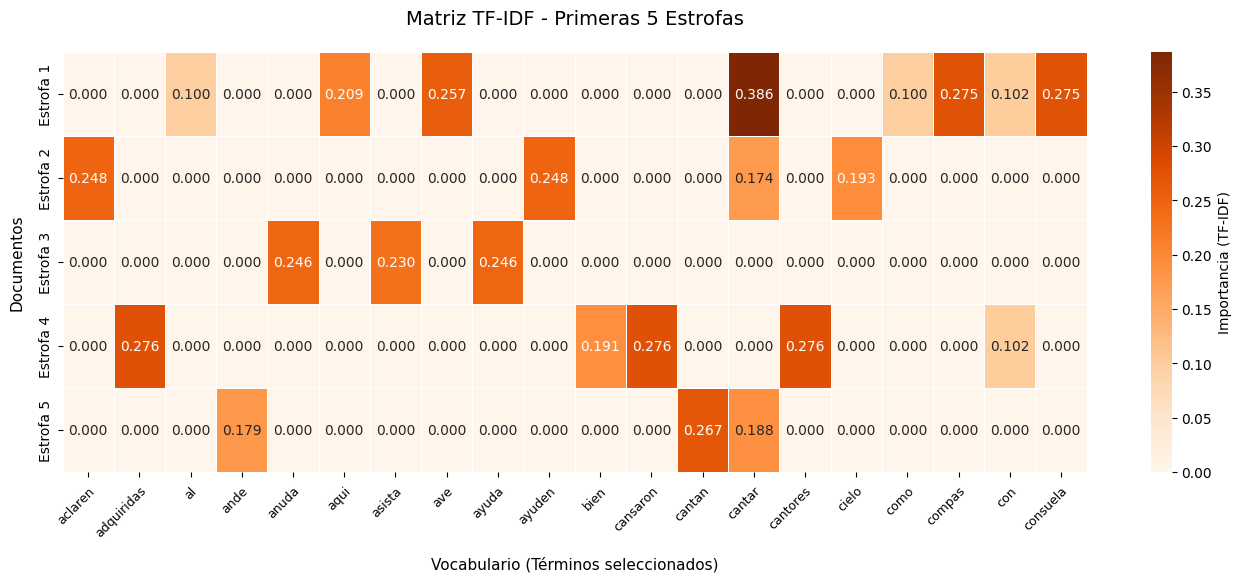

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
import random
import requests
import unicodedata

from sklearn.manifold import MDS
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from collections import defaultdict, Counter
from scipy.stats import gaussian_kde
from typing import Callable, Iterable

In [ ]:
class Corpus():
  def __init__(self, documents):
    self.raw_documents = documents

  def get_raw_documents(self):
    return self.raw_documents

  def sample(self, lenght=3):
    for i in range(min(lenght, len(self.raw_documents))):
      print(f'\n ==== Document {i+1} ==== \n\n{self.raw_documents[i][:250]}')

In [ ]:
class DocumentsCleaner():

    @staticmethod
    def _transform(
        documents: Iterable[str],
        function: Callable[[str], str],
        *,
        discard_empty: bool = False
    ) -> list[str]:
        """Aplica una transformación y devuelve una nueva lista."""
        result = [function(document) for document in documents]
        return [doc for doc in result if doc] if discard_empty else result

    def delete_init_final_chars(self, documents):
        """Elimina espacios al inicio y al final y descarta documentos vacíos."""
        return self._transform(
            documents, str.strip, discard_empty=True
        )

    def to_lower_case(self, documents):
        """Convierte los documentos a minúsculas."""
        return self._transform(documents, str.lower)

    def delete_accents(self, documents):
        """Elimina los diacríticos de los documentos."""
        def remove_accents(document):
            return ''.join(
                char
                for char in unicodedata.normalize('NFD', document)
                if unicodedata.category(char) != 'Mn'
            )

        return self._transform(documents, remove_accents)

    def conserve_letters_numbers_spaces_and_signs(self, documents):
        """Conserva los caracteres permitidos."""
        pattern = re.compile(r'[^a-zñ0-9\s.,;:¿?¡!"“”\'()\-—…]')

        return self._transform(
            documents,
            lambda document: pattern.sub('', document)
        )

    def normalize_multiple_spaces(self, documents):
        """Reduce los espacios consecutivos a uno solo."""
        return self._transform(
            documents,
            lambda document: re.sub(r'\s+', ' ', document).strip()
        )

    def conserve_documents_with_than_words(self, documents, n=5):
        """Conserva documentos con más de n palabras."""
        return [
            document
            for document in documents
            if document and len(document.split()) > n
        ]

    def apply_rgx(self, documents, rgx):
        """Descarta documentos que coinciden con el patrón
        o que tienen menos de dos líneas.
        """
        pattern = re.compile(rgx)

        return [
            document
            for document in documents
            if not pattern.match(document)
            and len(document.split('\n')) >= 2
        ]

In [ ]:
class Tokenizer():

  def tokenize(self, documents):
    """
    Separa palabras, números y signos de puntuación
    """
    tokenized_documents = []

    for i, doc in enumerate(documents):
        tokens = re.findall(r'\w+|[^\w\s]', doc, flags=re.UNICODE)
        tokenized_documents.append(tokens)

    self.tokens = tokenized_documents

  def get_tokens(self):
    return self.tokens

  def sample(self, lenght=3):
    for i in range(min(lenght, len(self.tokens))):
      print(f'\n ==== Document {i+1} ==== \n\n{self.tokens[i][:250]}')

In [ ]:
class TfIdf():

    def __init__(self, documents):
        self.documents = tuple(documents)

        self.vectorizer = TfidfVectorizer()
        self.tfidf_matrix = self.vectorizer.fit_transform(
            self.documents
        )

        self.tfidf_vocab = tuple(
            self.vectorizer.get_feature_names_out()
        )

        self.vocab_to_index = {
            word: index
            for index, word in enumerate(self.tfidf_vocab)
        }

    def map_vocab_to_index(self):
        """Devuelve el mapeo de palabras a columnas."""
        return self.vocab_to_index.copy()

    def get_word_vector(self, word):
        """Devuelve los pesos TF-IDF de una palabra en cada documento."""
        index = self.vocab_to_index.get(word)

        if index is None:
            raise ValueError(
                f"La palabra {word!r} no está en el vocabulario TF-IDF."
            )

        return self.tfidf_matrix[:, index].toarray().ravel()

    def search_similar(self, query, top_k=3):
        """Devuelve los documentos más similares a la consulta."""
        if top_k < 1:
            raise ValueError("top_k debe ser mayor que cero.")

        query_vector = self.vectorizer.transform([query])

        # La consulta no contiene términos del vocabulario.
        if query_vector.nnz == 0:
            return []

        similarities = cosine_similarity(
            query_vector,
            self.tfidf_matrix
        ).ravel()

        top_indices = np.argsort(
            -similarities,
            kind="stable"
        )[:top_k]

        return [
            (int(index), float(similarities[index]))
            for index in top_indices
            if similarities[index] > 0
        ]

    def to_pandas_df(self):
        """Convierte la matriz TF-IDF en un DataFrame."""
        return pd.DataFrame(
            self.tfidf_matrix.toarray(),
            columns=self.tfidf_vocab,
            index=[
                f"Estrofa {i + 1}"
                for i in range(len(self.documents))
            ]
        )

In [ ]:
# Paso 1 - Cargar, generar u obtener nuestro corpus (El universo de Documentos), como estamos trabajando con solo el Martin Fierro, nuestro corpus será cada una de las estrofas,
# que vamos a llamar documentos.

# URL del archivo JSON con las estrofas
url_json = 'https://raw.githubusercontent.com/Lautauro/fierrodiario/refs/heads/pages/json/estrofas.json'

print(f"Cargando datos desde {url_json}...")
response = requests.get(url_json)
response.raise_for_gradual_behavior = True # Asegura que la descarga sea correcta
data_json = response.json()


# Vamos a extraer los textos de las estrofas
raw_stanzas = []
if isinstance(data_json, dict) and 'estrofas' in data_json:
    # Si es un diccionario con la key 'estrofas'
    raw_stanzas = [item.get('texto', '') if isinstance(item, dict) else str(item) for item in data_json['estrofas']]
elif isinstance(data_json, list):
    # Si es una lista directamente
    raw_stanzas = [item.get('texto', '') if isinstance(item, dict) else str(item) for item in data_json]

corpus = Corpus(raw_stanzas)

corpus.sample(lenght=5)

Cargando datos desde https://raw.githubusercontent.com/Lautauro/fierrodiario/refs/heads/pages/json/estrofas.json...

 ==== Document 1 ==== 

Aquí me pongo á cantar
Al compás de la vigüela,
Que el hombre que lo desvela
Una pena estraordinaria,
Como la ave solitaria
Con el cantar se consuela.

 ==== Document 2 ==== 

Pido á los Santos del Cielo
Que ayuden mi pensamiento,
Les pido en este momento
Que voy á cantar mi historia
Me refresquen la memoria
Y aclaren mi entendimiento.

 ==== Document 3 ==== 

Vengan Santos milagrosos,
Vengan todos en mi ayuda,
Que la lengua se me añuda
Y se me turba la vista;
Pido á mi Dios que me asista
En una ocasión tan ruda.

 ==== Document 4 ==== 

Yo he visto muchos cantores,
Con famas bien otenidas,
Y que despues de adquiridas
No las quieren sustentar:
Parece que sin largar
Se cansaron en partidas.

 ==== Document 5 ==== 

Mas ande otro criollo pasa
Martin Fierro ha de pasar,
Nada lo hace recular
Ni las fantasmas lo espantan;
Y dende que todos cantan
Yo ta

In [ ]:
# Paso 2 - Limpieza de nuestro corpus

raw_documents = corpus.get_raw_documents()

cleaner = DocumentsCleaner()

cleaned_documents = cleaner.delete_init_final_chars(raw_documents)
cleaned_documents = cleaner.to_lower_case(cleaned_documents)
cleaned_documents = cleaner.delete_accents(cleaned_documents)
cleaned_documents = cleaner.normalize_multiple_spaces(cleaned_documents)

total_documents = len(cleaned_documents)

print(f'Total de documentos limpiados: {total_documents}')
print("Documentos únicos:", len(set(cleaned_documents)))
print('\nEjemplos:')
for i in range(min(3, total_documents)):
    print(f'\nDocumento {i+1}: {cleaned_documents[i][:250]}')

Total de documentos limpiados: 398
Documentos únicos: 398

Ejemplos:

Documento 1: aqui me pongo a cantar al compas de la viguela, que el hombre que lo desvela una pena estraordinaria, como la ave solitaria con el cantar se consuela.

Documento 2: pido a los santos del cielo que ayuden mi pensamiento, les pido en este momento que voy a cantar mi historia me refresquen la memoria y aclaren mi entendimiento.

Documento 3: vengan santos milagrosos, vengan todos en mi ayuda, que la lengua se me anuda y se me turba la vista; pido a mi dios que me asista en una ocasion tan ruda.


In [ ]:
# Paso 3 - Tokenizar ej. aqui me pongo a cantar -> ['aqui', 'me', 'pongo', 'a', 'cantar']

tokenizer = Tokenizer()

tokenizer.tokenize(cleaned_documents)

tokenizer.sample(lenght=5)

tokenized_documents = tokenizer.get_tokens()

# Podemos notar, que en nuestros ejemplos hay tokens que se repiten, por ej la coma ','.
# ¿Por qué no conviene eliminar los duplicados ahora?
# Si conviertes cada documento en un set, perderás información importante:
#  Frecuencia: no sabrás cuántas veces aparece una palabra.
#  Orden: no podrás reconstruir los versos ni estudiar secuencias de palabras.
#  Contexto: dificultarás el entrenamiento de modelos de lenguaje, como los modelos de n-gramas.


 ==== Document 1 ==== 

['aqui', 'me', 'pongo', 'a', 'cantar', 'al', 'compas', 'de', 'la', 'viguela', ',', 'que', 'el', 'hombre', 'que', 'lo', 'desvela', 'una', 'pena', 'estraordinaria', ',', 'como', 'la', 'ave', 'solitaria', 'con', 'el', 'cantar', 'se', 'consuela', '.']

 ==== Document 2 ==== 

['pido', 'a', 'los', 'santos', 'del', 'cielo', 'que', 'ayuden', 'mi', 'pensamiento', ',', 'les', 'pido', 'en', 'este', 'momento', 'que', 'voy', 'a', 'cantar', 'mi', 'historia', 'me', 'refresquen', 'la', 'memoria', 'y', 'aclaren', 'mi', 'entendimiento', '.']

 ==== Document 3 ==== 

['vengan', 'santos', 'milagrosos', ',', 'vengan', 'todos', 'en', 'mi', 'ayuda', ',', 'que', 'la', 'lengua', 'se', 'me', 'anuda', 'y', 'se', 'me', 'turba', 'la', 'vista', ';', 'pido', 'a', 'mi', 'dios', 'que', 'me', 'asista', 'en', 'una', 'ocasion', 'tan', 'ruda', '.']

 ==== Document 4 ==== 

['yo', 'he', 'visto', 'muchos', 'cantores', ',', 'con', 'famas', 'bien', 'otenidas', ',', 'y', 'que', 'despues', 'de', 'adqui

In [ ]:
# 1. Inicializar TfidfVectorizer y calcular la matriz TF-IDF completa
tfidf = TfIdf(cleaned_documents)

tfidf_matrix_full = tfidf.tfidf_matrix
tfidf_vocab_full = tfidf.tfidf_vocab

df_tfidf_full = tfidf.to_pandas_df()

print(f"Dimensiones de la Matriz TF-IDF: {df_tfidf_full.shape}") # 398 estrofas x 2786 palabras únicas
print(f"Total de palabras en el vocabulario: {len(tfidf_vocab_full)}")

Dimensiones de la Matriz TF-IDF: (398, 2787)
Total de palabras en el vocabulario: 2787


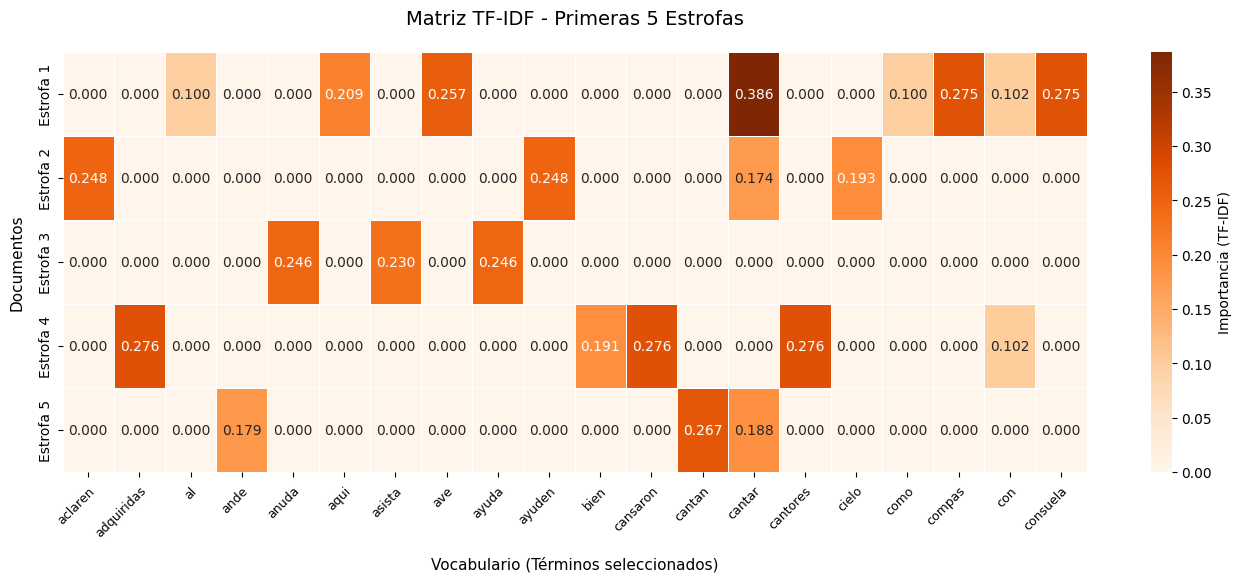

In [ ]:
# 2. Seleccionar términos presentes en las primeras 5 estrofas
subset_docs_comp = df_tfidf_full.iloc[:5]
present_terms_comp = subset_docs_comp.columns[
    (subset_docs_comp > 0).any(axis=0)
]

vis_terms = list(present_terms_comp)[:20]

# 3. Crear el mapa de calor
fig, ax = plt.subplots(figsize=(16, 7))

sns.heatmap(
    df_tfidf_full.iloc[:5][vis_terms],
    annot=True,
    fmt='.3f',
    cmap='Oranges',
    linewidths=0.5,
    linecolor='white',
    ax=ax,
    cbar_kws={'label': 'Importancia (TF-IDF)'}
)

# 4. Configurar título y etiquetas
ax.set_title(
    'Matriz TF-IDF - Primeras 5 Estrofas',
    fontsize=14,
    pad=20
)

ax.set_ylabel('Documentos', fontsize=11, labelpad=10)
ax.set_xlabel(
    'Vocabulario (Términos seleccionados)',
    fontsize=11,
    labelpad=12
)

# 5. Alinear las etiquetas del eje X
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    ha='right',
    rotation_mode='anchor'
)

ax.tick_params(axis='x', labelsize=9, pad=5)
ax.tick_params(axis='y', labelsize=10)

# 6. Ajustar los márgenes para evitar superposiciones
fig.subplots_adjust(
    left=0.12,
    right=0.92,
    top=0.88,
    bottom=0.28
)

plt.show()

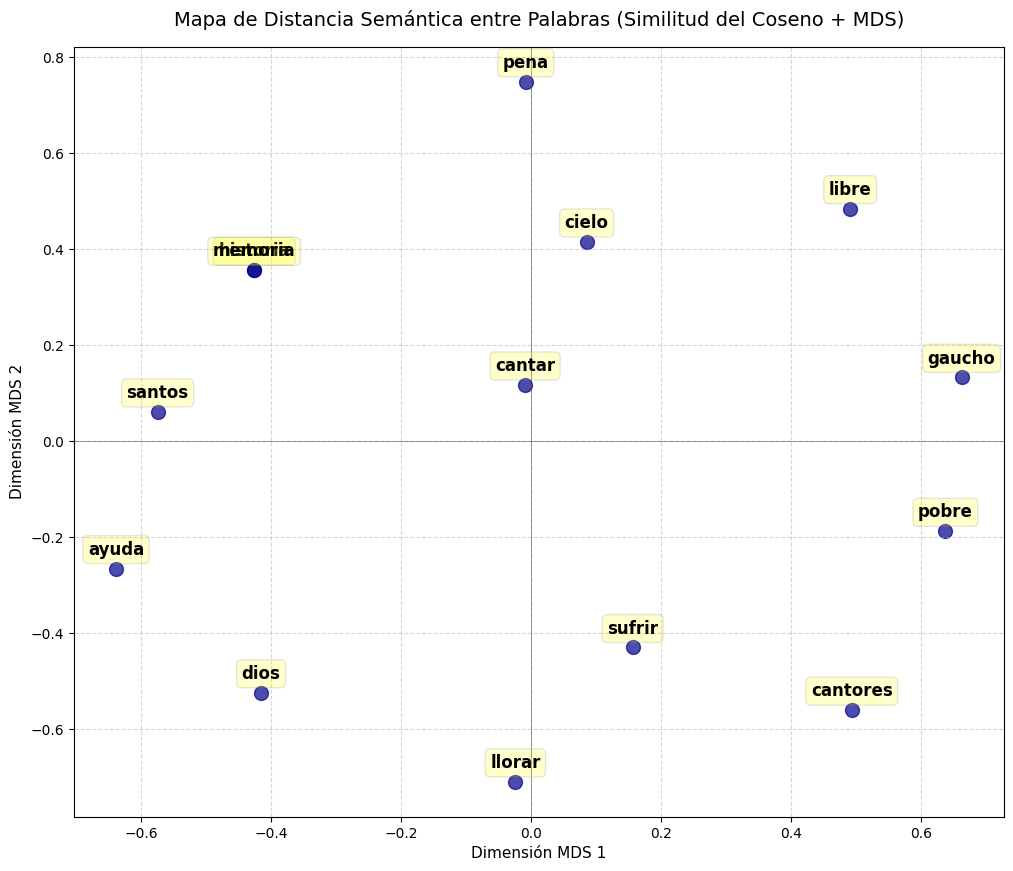

In [ ]:
# 1. Seleccionamos un conjunto de palabras clave interesantes del Martín Fierro
palabras_objetivo = [
    'cantar', 'cantores', 'historia', 'memoria',
    'santos', 'cielo', 'dios', 'ayuda',
    'pena', 'sufrir', 'llorar', 'pobre',
    'gaucho', 'libre'
]

# Filtrar solo las palabras que existen en nuestro vocabulario TF-IDF
vocab_list = list(tfidf_vocab_full)
palabras_validas = [p for p in palabras_objetivo if p in vocab_list]

vectores_seleccionados = np.array([
    tfidf.get_word_vector(palabra)
    for palabra in palabras_validas
])

# 3. Calcular la matriz de similitud del coseno entre estas palabras
matriz_similitud = cosine_similarity(vectores_seleccionados)

# Convertir similitud a distancia (Distancia de Coseno = 1 - Similitud de Coseno)
matriz_distancia = 1 - matriz_similitud

# 4. Proyectar las distancias a 2D usando MDS (Multi-dimensional Scaling)
mds = MDS(n_components=2, dissimilarity='precomputed', random_state=42)
posiciones_2d = mds.fit_transform(matriz_distancia)

# 5. Graficar las palabras en el plano 2D
plt.figure(figsize=(12, 10))
plt.scatter(posiciones_2d[:, 0], posiciones_2d[:, 1], color='darkblue', s=100, alpha=0.7)

# Añadir etiquetas a cada punto
for i, palabra in enumerate(palabras_validas):
    plt.annotate(
        palabra,
        (posiciones_2d[i, 0], posiciones_2d[i, 1]),
        textcoords="offset points",
        xytext=(0,10),
        ha='center',
        fontsize=12,
        weight='bold',
        bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.2, ec="gray")
    )

plt.title('Mapa de Distancia Semántica entre Palabras (Similitud del Coseno + MDS)', fontsize=14, pad=15)
plt.xlabel('Dimensión MDS 1', fontsize=11)
plt.ylabel('Dimensión MDS 2', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.axhline(0, color='black',linewidth=0.5, alpha=0.5)
plt.axvline(0, color='black',linewidth=0.5, alpha=0.5)
plt.show()


### 🧠 Análisis del Gráfico y Limitaciones de TF-IDF

A primera vista, resulta contraintuitivo que palabras como **"santos"** y **"cielo"** o **"dios"** aparezcan distantes en nuestro mapa semántico, cuando lógicamente están muy relacionadas.

#### ¿Por qué "santos" y "cielo" aparecen separados?
1. **Dependencia estricta de la coocurrencia:** TF-IDF no entiende el significado real de las palabras; solo registra si aparecen juntas en las mismas estrofas (documentos). Si la palabra "santos" se usa principalmente en la Estrofa 3 ("*Vengan Santos milagrosos...*") y "cielo" se usa en la Estrofa 16 ("*Como el pájaro del Cielo...*"), para el algoritmo estas palabras pertenecen a mundos distintos, ignorando por completo que conceptualmente están vinculadas.
2. **Tamaño de los documentos:** Como nuestras estrofas son cortas (documentos de apenas 6 versos), la probabilidad de que compartan exactamente las mismas palabras disminuye notablemente en comparación con textos más largos como capítulos enteros.

#### El Problema de utilizar TF-IDF (Limitaciones):
* **Falta de Semántica Real (Problema de Sinonimia):** Si una estrofa usa "lamento" y otra usa "queja", TF-IDF las tratará como palabras 100% independientes, con una similitud del coseno de 0, a pesar de ser sinónimos.
* **No detecta el orden ni la sintaxis:** Al ser un modelo basado en bolsa de palabras (*Bag of Words*), ignora el orden de los términos. "El gaucho no es malo" y "El malo no es gaucho" producen exactamente el mismo vector.
* **Vocabulario Rígido:** No puede generalizar. Si buscamos una palabra que no está en el vocabulario original (como "celestial"), la similitud será cero absoluto.
* **La Maldición de la Dimensión:** Genera matrices gigantescas y sumamente dispersas (muchos ceros), lo que hace que requiera técnicas de proyección como MDS o PCA para visualizarse, perdiendo información en el proceso.

TF-IDF es el corazón de los primeros **motores de búsqueda**.
También se usa para:

- **Resumen automático**: extraer las frases más representativas
- **Clasificación de documentos**: encontrar palabras clave por categoría
- **Búsqueda semántica básica**: recuperar documentos relevantes dado un *query*

El proceso es idéntico al BoW pero los vectores son más informativos porque ponderan
la rareza de cada término dentro del corpus.

In [ ]:
# ── Motor de búsqueda con TF-IDF ──

# Consulta de prueba
query = 'cantar pena solitaria voy'
print(f"🔍 Consulta: '{query}'\n")
print('📜 Estrofas más similares según BoW:\n')

# Obtiene los índices de las mejores coincidencias
resultados = tfidf.search_similar(query, 5)
for j, (idx, sim) in enumerate(resultados, 1):
    print(f'[{j}] Similitud: {sim:.4f} (Estrofa {idx+1})')
    print(f'     {cleaned_documents[idx][:180]}...')
    print()

🔍 Consulta: 'cantar pena solitaria voy'

📜 Estrofas más similares según BoW:

[1] Similitud: 0.4507 (Estrofa 1)
     aqui me pongo a cantar al compas de la viguela, que el hombre que lo desvela una pena estraordinaria, como la ave solitaria con el cantar se consuela....

[2] Similitud: 0.1922 (Estrofa 297)
     y con algunos ardiles voy viviendo, aunque rotoso; a veces me hago el sarnoso y no tengo ni un granito, pero al chifle voy ganoso como panzon al maiz frito....

[3] Similitud: 0.1669 (Estrofa 2)
     pido a los santos del cielo que ayuden mi pensamiento, les pido en este momento que voy a cantar mi historia me refresquen la memoria y aclaren mi entendimiento....

[4] Similitud: 0.1639 (Estrofa 220)
     y dicen que dende entonces cuando es la noche serena, suele verse una luz mala como de alma que anda en pena....

[5] Similitud: 0.1475 (Estrofa 7)
     que no se trabe mi lengua ni me falte la palabra— el cantar mi gloria labra y poniendome a cantar, cantando me han de encontrar

### Material Complementario
- [TF-IDF ¡EXPLICADO!: pre-procesamiento de texto](https://www.youtube.com/watch?v=ScPXc3ibHFU)
- [Tutorial: NORMALIZACIÓN de texto con TF-IDF](https://www.youtube.com/watch?v=vMfxw9aghAo)
- [Understanding TF-IDF: A Traditional Approach to Feature Extraction in NLP](https://medium.com/data-science/understanding-tf-idf-a-traditional-approach-to-feature-extraction-in-nlp-a5bfbe04723f)